##Project - Hakim Ziyech

Project made to analyse Hakim Ziyech's actions with the ball during the Fifa World Cup 2022.

Done with data from StatsBomb

**Presentation and further details about the project [on this link](https://drive.google.com/file/d/1uqru2pPwINixbgmRWyGQrozRnn_WH837/view?usp=sharing)**



---


# Importing packages and data

Importing the statsbombpy and the mplsoccer packages. The former will be used to get the data from StatsBomb, while the latter will be used to plot the visualizations



In [1]:
pip install statsbombpy

In [2]:
pip install mplsoccer

Importing libraries that will be used during the analysis

In [3]:
import pandas as pd
from statsbombpy import sb
from mplsoccer import Pitch
import numpy as np

# Filtering

In [4]:
sb.competitions()

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,9,281,Germany,1. Bundesliga,male,False,False,2023/2024,2024-09-28T20:46:38.893391,2025-11-15T23:17:41.827093,2025-11-15T23:17:41.827093,2024-09-28T20:46:38.893391
1,9,27,Germany,1. Bundesliga,male,False,False,2015/2016,2024-05-19T11:11:14.192381,None,None,2024-05-19T11:11:14.192381
2,1267,107,Africa,African Cup of Nations,male,False,True,2023,2026-05-12T21:18:08.827431,2026-05-02T02:07:18.902396,2026-05-02T02:07:18.902396,2026-05-12T21:18:08.827431
3,16,4,Europe,Champions League,male,False,False,2018/2019,2026-05-15T15:54:04.598614,2021-06-13T16:17:31.694,None,2026-05-15T15:54:04.598614
4,16,1,Europe,Champions League,male,False,False,2017/2018,2024-02-13T02:35:28.134882,2021-06-13T16:17:31.694,None,2024-02-13T02:35:28.134882
...,...,...,...,...,...,...,...,...,...,...,...,...
75,35,75,Europe,UEFA Europa League,male,False,False,1988/1989,2026-04-11T12:48:10.012987,2021-06-13T16:17:31.694,None,2026-04-11T12:48:10.012987
76,53,315,Europe,UEFA Women's Euro,female,False,True,2025,2026-04-27T22:02:42.690507,2026-04-27T22:03:28.087062,2026-04-27T22:03:28.087062,2026-04-27T22:02:42.690507
77,53,106,Europe,UEFA Women's Euro,female,False,True,2022,2026-05-05T03:03:04.199896,2026-05-05T03:05:32.480837,2026-05-05T03:05:32.480837,2026-05-05T03:03:04.199896
78,72,107,International,Women's World Cup,female,False,True,2023,2026-05-03T13:51:31.021141,2026-05-03T13:55:52.303219,2026-05-03T13:55:52.303219,2026-05-03T13:51:31.021141


After checking all competitions that StatsBomb made available, I chose to get all the data from passes at the 2022 FIFA World Cup



In [5]:
events = sb.competition_events(
    country="International",
    division= "FIFA World Cup",
    season="2022",
    gender="male"
)

grouped_events = sb.competition_events(
    country="International",
    division= "FIFA World Cup",
    season="2022",
    split=True
)
grouped_events["passes"]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,pass_technique,pass_miscommunication,pass_goal_assist,pass_through_ball,counterpress,pass_outswinging,out,pass_cut_back,pass_straight,pass_no_touch
0,05a57281-9295-408a-9c4f-e32d7fad4d96,5,1,00:00:00.460,0,0,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3a06bcce-1408-4a0b-be01-f6b93f142b30,8,1,00:00:02.415,0,2,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1f1b0ef8-1a1d-45b3-bf9c-4299ea836377,11,1,00:00:05.143,0,5,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,84cdb79d-76e6-408a-bbc4-34026594624a,14,1,00:00:08.720,0,8,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,28e07622-dd23-4af6-8439-cb9856c545db,17,1,00:00:12.122,0,12,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68510,5b024df9-2d62-4513-bb1b-fa3588644271,3364,2,00:51:40.878,96,40,Pass,155,South Korea,From Throw In,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68511,b124b025-61d7-4df2-8438-c564d20ef858,3367,2,00:51:42.163,96,42,Pass,155,South Korea,From Throw In,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68512,3b68b936-010c-4b69-927c-8568f3a22fc6,3370,2,00:51:43.533,96,43,Pass,155,South Korea,From Throw In,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68513,82c6aa14-4d63-43f5-b030-a203612cf383,3372,2,00:51:44.180,96,44,Pass,155,South Korea,From Throw In,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df = grouped_events["passes"]

Splitting the 'location' and 'end_location' columns to get the 'x' and 'y' coordinates from each pass (at its start and also at its end) in different columns

In [7]:
df[['x_start', 'y_start']] = pd.DataFrame(df.location.tolist(), index = df.index)
df[['x_end', 'y_end']] = pd.DataFrame(df.pass_end_location.tolist(), index = df.index)

After filtering the pass events, I selected Hakim Ziyech, from Morocco, to be the focal point of the analysis. Then I used the 'columns' property to have a better understanting of the content in this dataframe

In [8]:
ziyech_passes = df[df['player'] == 'Hakim Ziyech']

In [9]:
ziyech_passes

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,counterpress,pass_outswinging,out,pass_cut_back,pass_straight,pass_no_touch,x_start,y_start,x_end,y_end
7,86f844fd-44b9-4377-8eae-cd2ab5242d6b,27,1,00:00:18.477,0,18,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,37.3,78.2,29.0,79.6
14,8beafe4f-d282-4fb7-a2cd-6e00dc95160a,49,1,00:00:45.689,0,45,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,100.0,75.6,86.7,69.5
16,187e3b88-85a6-4a14-a10c-2cb5a73def7a,55,1,00:00:50.973,0,50,Pass,2,Morocco,From Kick Off,...,NaN,NaN,NaN,NaN,NaN,NaN,105.9,70.9,111.9,47.9
25,da5afb4a-b9a7-45e7-8381-a91d8d6df8ef,88,1,00:01:53.267,1,53,Pass,5,Morocco,Regular Play,...,NaN,NaN,NaN,NaN,NaN,NaN,56.7,78.0,50.8,66.4
67,60c60544-e7da-4569-9298-928d658cdb31,233,1,00:05:40.870,5,40,Pass,11,Morocco,From Free Kick,...,NaN,NaN,NaN,NaN,NaN,NaN,38.7,78.2,38.7,73.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58983,8264b49d-5ca8-4b1f-b53a-ca10bd1a9095,3065,2,00:33:02.333,78,2,Pass,128,Morocco,From Goal Kick,...,True,NaN,NaN,NaN,NaN,NaN,64.0,62.4,46.7,45.5
59049,75dbcf06-1118-4a2a-b3f7-76f8525076ac,3290,2,00:39:35.881,84,35,Pass,138,Morocco,From Goal Kick,...,NaN,NaN,NaN,NaN,NaN,NaN,93.1,16.8,105.5,41.9
59073,6b5658b3-d2ab-4cce-9f49-b1ef52e0061a,3375,2,00:41:02.641,86,2,Pass,142,Morocco,Regular Play,...,NaN,NaN,NaN,NaN,NaN,NaN,32.1,20.9,24.9,18.1
59117,ab1b09fc-59c3-4e2c-a947-99b492107ec8,3528,2,00:45:36.249,90,36,Pass,149,Morocco,From Corner,...,NaN,NaN,NaN,NaN,NaN,NaN,120.0,0.1,118.1,3.1


In [10]:
ziyech_passes.columns

Index(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type',
       'possession', 'possession_team', 'play_pattern', 'team', 'player',
       'position', 'location', 'duration', 'related_events', 'match_id',
       'pass_recipient', 'pass_length', 'pass_angle', 'pass_height',
       'pass_end_location', 'pass_body_part', 'pass_type',
       'possession_team_id', 'team_id', 'player_id', 'pass_recipient_id',
       'pass_switch', 'pass_cross', 'pass_outcome', 'off_camera',
       'under_pressure', 'pass_assisted_shot_id', 'pass_shot_assist',
       'pass_deflected', 'pass_aerial_won', 'pass_inswinging',
       'pass_technique', 'pass_miscommunication', 'pass_goal_assist',
       'pass_through_ball', 'counterpress', 'pass_outswinging', 'out',
       'pass_cut_back', 'pass_straight', 'pass_no_touch', 'x_start', 'y_start',
       'x_end', 'y_end'],
      dtype='object')

# All passes

In this step, I wanted to visualize where Ziyech most passed the ball on the pitch. Below I checked the unique values from the 'pass_outcome' column to distinguish the completed from the incomplete passes

In [11]:
ziyech_passes['pass_outcome'].unique()

array([nan, 'Incomplete', 'Out', 'Pass Offside'], dtype=object)

In the two cells below I created two different dataframes. The first filters only rows with null values in the 'pass_outcome' column. These rows describe completed passes. The second dataframe filters the passes that were not completed

In [12]:
ziyech_passes_comp = ziyech_passes[ziyech_passes['pass_outcome'].isna()]

ziyech_passes_incomp = ziyech_passes[ziyech_passes['pass_outcome'].notnull()]

Plotting all the passes from Ziyech during the FIFA World Cup 2022, categorizing them according to their outcome (complete or incomplete)


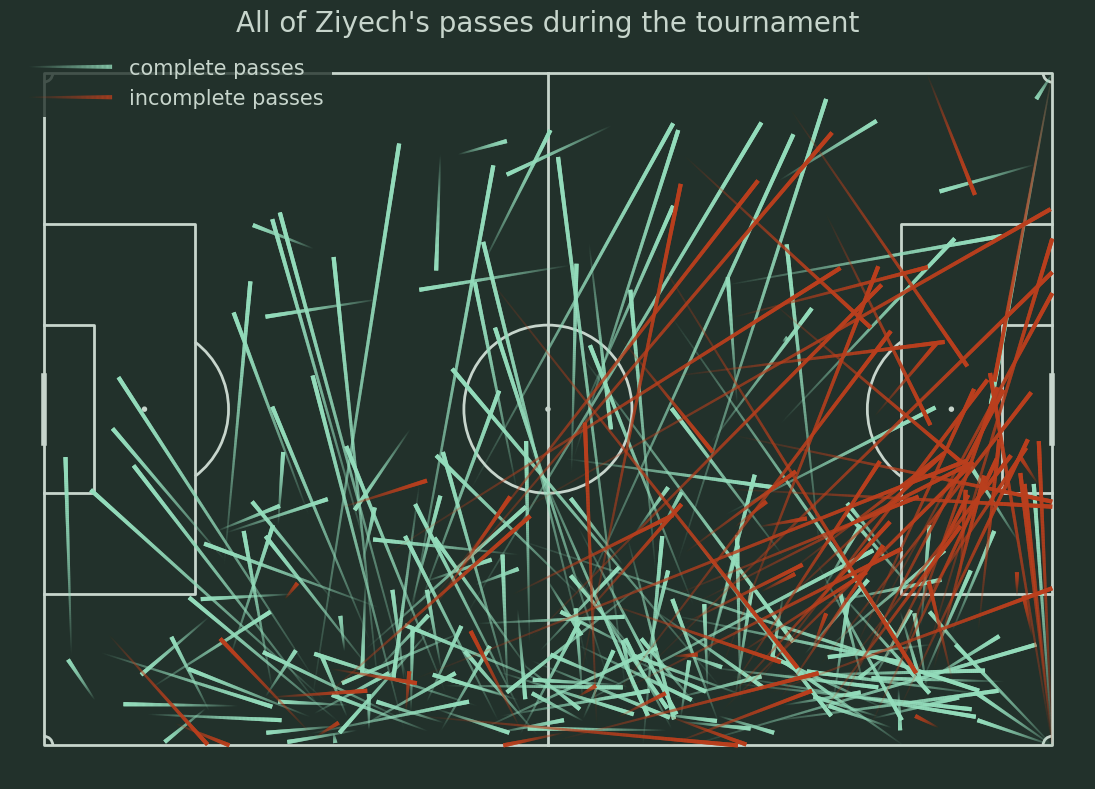

In [13]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_passes_comp['x_start'], ziyech_passes_comp['y_start'], ziyech_passes_comp['x_end'], ziyech_passes_comp['y_end'],
            ax = ax, color = '#94DDBC', lw = 3, transparent = True, comet = True, label = 'complete passes')

pitch.lines(ziyech_passes_incomp['x_start'], ziyech_passes_incomp['y_start'], ziyech_passes_incomp['x_end'], ziyech_passes_incomp['y_end'],
            ax = ax, color = '#BA3F1D', lw = 3, transparent = True, comet = True, label = 'incomplete passes')

ax_title = ax.set_title("All of Ziyech's passes during the tournament", fontsize = 20, color = '#c7d5cc')

ax.legend(facecolor='#22312b', edgecolor='None', fontsize=15, labelcolor = '#c7d5cc', loc='upper left', handlelength=4)

# Progressive passes

The definition of progressive passes may vary according to the data provider. In this case, I'll consider them as open-play passes that move the ball at least 25% closer to the goal from its origin. To figure out which of passes were progressive or not, I initially need to calculate the distance from the center of the opponent's goal to the starting point and the ending point of the pass

In the cell below I'll use the dataframe with every pass attempted during the FIFA World Cup 2022 to find out how Ziyech ranks among all players in progressive passes

In [14]:
df['start'] = np.sqrt(np.square(120 - df['x_start']) + np.square(40 - df['y_start']))
df['end'] = np.sqrt(np.square(120 - df['x_end']) + np.square(40 - df['y_end']))

If the difference from the starting point to the ending point of the pass move the ball at least 25% closer to the center of the opponent's goal, the new column created below ('progressive') gets a True boolean value. If not, the boolean value is False

In [15]:
df['progressive'] = [(df['end'].iloc[x]) / (df['start'].iloc[x]) < .75 for x in range(len(df.start))]

In [16]:
prog = df[df['progressive'] == True]

In [17]:
prog['pass_type'].unique()

array([nan, 'Recovery', 'Throw-in', 'Corner', 'Free Kick', 'Goal Kick',
       'Interception'], dtype=object)

I created the variable 'prog' to filter only the progressive passes and below excluded every attempt that came off a recovery, corner, goal kick, throw-in, free kick and interception. Otherwise, the number of progressive passes listed could be deceiving

In [18]:
prog = prog[prog['pass_type'].isna()]

In [19]:
import pandas as pd
# Configura o pandas para exibir todas as colunas do DataFrame sem truncar
pd.set_option('display.max_columns', None)

# Exibe as primeiras linhas do DataFrame prog com todas as colunas visíveis
display(prog.head())


,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,team,player,position,location,duration,related_events,match_id,pass_recipient,pass_length,pass_angle,pass_height,pass_end_location,pass_body_part,pass_type,possession_team_id,team_id,player_id,pass_recipient_id,pass_switch,pass_cross,pass_outcome,off_camera,under_pressure,pass_assisted_shot_id,pass_shot_assist,pass_deflected,pass_aerial_won,pass_inswinging,pass_technique,pass_miscommunication,pass_goal_assist,pass_through_ball,counterpress,pass_outswinging,out,pass_cut_back,pass_straight,pass_no_touch,x_start,y_start,x_end,y_end,start,end,progressive
11,8884ba29-2e18-47ad-9e00-36ec09801f6d,40,1,00:00:30.091,0,30,Pass,2,Morocco,From Kick Off,Morocco,Romain Saïss,Left Center Back,"[22.7, 7.2]",3.699825,[0e7c4e29-da3c-41eb-8784-b91cfd79444a],3857276,Abdelhamid Sabiri,70.044630,-0.035699,High Pass,"[92.7, 4.7]",Left Foot,NaN,788,788,5219,3634.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.7,7.2,92.7,4.7,102.679745,44.624881,True
16,187e3b88-85a6-4a14-a10c-2cb5a73def7a,55,1,00:00:50.973,0,50,Pass,2,Morocco,From Kick Off,Morocco,Hakim Ziyech,Right Wing,"[105.9, 70.9]",0.913447,"[46e8af19-5ad8-4c04-a7fe-69f71d40c31e, 7039a2d...",3857276,Youssef En-Nesyri,23.769728,-1.315614,High Pass,"[111.9, 47.9]",Right Foot,NaN,788,788,5237,6301.0,NaN,True,Incomplete,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,105.9,70.9,111.9,47.9,33.964982,11.314592,True
19,e5cdf1a0-28c3-440b-8943-d25733a5e924,68,1,00:01:36.260,1,36,Pass,4,Canada,From Goal Kick,Canada,Kamal Miller,Left Center Back,"[17.5, 22.9]",2.758721,"[6c12de92-6d06-46da-bdb2-3fe0ede357ab, c0bd8db...",3857276,Cyle Larin,51.665268,0.485289,High Pass,"[63.2, 47.0]",Left Foot,NaN,1833,1833,23828,16459.0,NaN,NaN,Incomplete,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.5,22.9,63.2,47.0,103.916601,57.229713,True
27,be2d11a3-9bc4-471b-9558-5f92975eea05,93,1,00:01:57.516,1,57,Pass,6,Canada,Regular Play,Canada,Cyle Larin,Center Forward,"[77.3, 35.9]",1.431966,[e8f4a45b-93f3-4229-a5c0-5e90fe3f8893],3857276,Alphonso Davies,20.777151,0.569313,Ground Pass,"[94.8, 47.1]",Right Foot,NaN,1833,1833,16459,12365.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.3,35.9,94.8,47.1,42.896387,26.181100,True
36,8a9d61a9-ace5-47a7-8660-7456bf147693,133,1,00:02:24.438,2,24,Pass,7,Morocco,Regular Play,Morocco,Sofyan Amrabat,Center Defensive Midfield,"[52.9, 24.1]",1.508081,[9cb37bdc-17dc-4184-9ffd-a837ab815f52],3857276,Sofiane Boufal,36.529987,-0.546992,Low Pass,"[84.1, 5.1]",Right Foot,NaN,788,788,5234,3625.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.9,24.1,84.1,5.1,68.958103,50.068154,True


Grouping the dataframe by the player name and then getting the top values in this attribute

In [20]:
prog_players = prog.groupby(['player', 'team']).count().sort_values(['id'], ascending = False).reset_index()[['player', 'team', 'id']]

In [21]:
prog_players.rename(columns = {'id':'prog'}, inplace = True)

In [22]:
prog_players.head(10)

,player,team,prog
0,Lionel Andrés Messi Cuccittini,Argentina,65
1,Rodrigo Javier De Paul,Argentina,64
2,Luka Modrić,Croatia,62
3,Daley Blind,Netherlands,60
4,Hakim Ziyech,Morocco,56
5,Ivan Perišić,Croatia,55
6,Josip Juranović,Croatia,54
7,Wojciech Szczęsny,Poland,54
8,Joško Gvardiol,Croatia,52
9,In-Beom Hwang,South Korea,51


I also wanted to check the percentage that the player's progressive passes represent amont their team's total progressive passes numbers. Below I grouped the 'prog' dataframe, but by the team, instead of the player names

In [23]:
prog_teams = prog_players[['team', 'prog']].groupby(['team']).sum().sort_values(['prog'], ascending = False).reset_index()

In [24]:
prog_teams.head()

,team,prog
0,Croatia,521
1,Argentina,474
2,France,431
3,Morocco,370
4,Portugal,369


Merging the tables to get player and team values side by side and them adding a new column to indicate how much the individual value represent in the squad

In [25]:
prog_complete = pd.merge(prog_players, prog_teams, how = 'left', on = 'team')

In [26]:
prog_complete.rename(columns = {'prog_x':'prog_player', 'prog_y':'prog_team'}, inplace = True)

In [27]:
prog_complete.head(10)

,player,team,prog_player,prog_team
0,Lionel Andrés Messi Cuccittini,Argentina,65,474
1,Rodrigo Javier De Paul,Argentina,64,474
2,Luka Modrić,Croatia,62,521
3,Daley Blind,Netherlands,60,357
4,Hakim Ziyech,Morocco,56,370
5,Ivan Perišić,Croatia,55,521
6,Josip Juranović,Croatia,54,521
7,Wojciech Szczęsny,Poland,54,229
8,Joško Gvardiol,Croatia,52,521
9,In-Beom Hwang,South Korea,51,304


In [28]:
prog_complete['prog%'] = prog_complete['prog_player'] / prog_complete['prog_team'] * 100
prog_complete.sort_values('prog%', ascending = False).head(15)

,player,team,prog_player,prog_team,prog%
7,Wojciech Szczęsny,Poland,54,229,23.580786
63,Keylor Navas Gamboa,Costa Rica,31,149,20.805369
48,Mohamed Salisu,Ghana,35,182,19.230769
33,Kevin De Bruyne,Belgium,39,203,19.211823
12,Mathew Ryan,Australia,49,272,18.014706
3,Daley Blind,Netherlands,60,357,16.806723
9,In-Beom Hwang,South Korea,51,304,16.776316
19,Joachim Andersen,Denmark,43,261,16.475096
74,Abdulelah Al Amri,Saudi Arabia,30,185,16.216216
60,Hirving Rodrigo Lozano Bahena,Mexico,32,202,15.841584


Creating a new variable to filter only Ziyech's progressive passes during the competition

In [29]:
ziyech_prog = prog[prog['player'] == 'Hakim Ziyech']
ziyech_prog.shape

(56, 55)

In [30]:
ziyech_prog_comp = ziyech_prog[ziyech_prog['pass_outcome'].isna()]
ziyech_prog_comp.shape


(22, 55)

In [31]:
ziyech_prog_incomp = ziyech_prog[ziyech_prog['pass_outcome'].notnull()]
ziyech_prog_incomp.shape

(34, 55)

Plotting all progressive passes from Ziyech during the FIFA World Cup 2022, categorizing them according to their outcome (complete or incomplete)



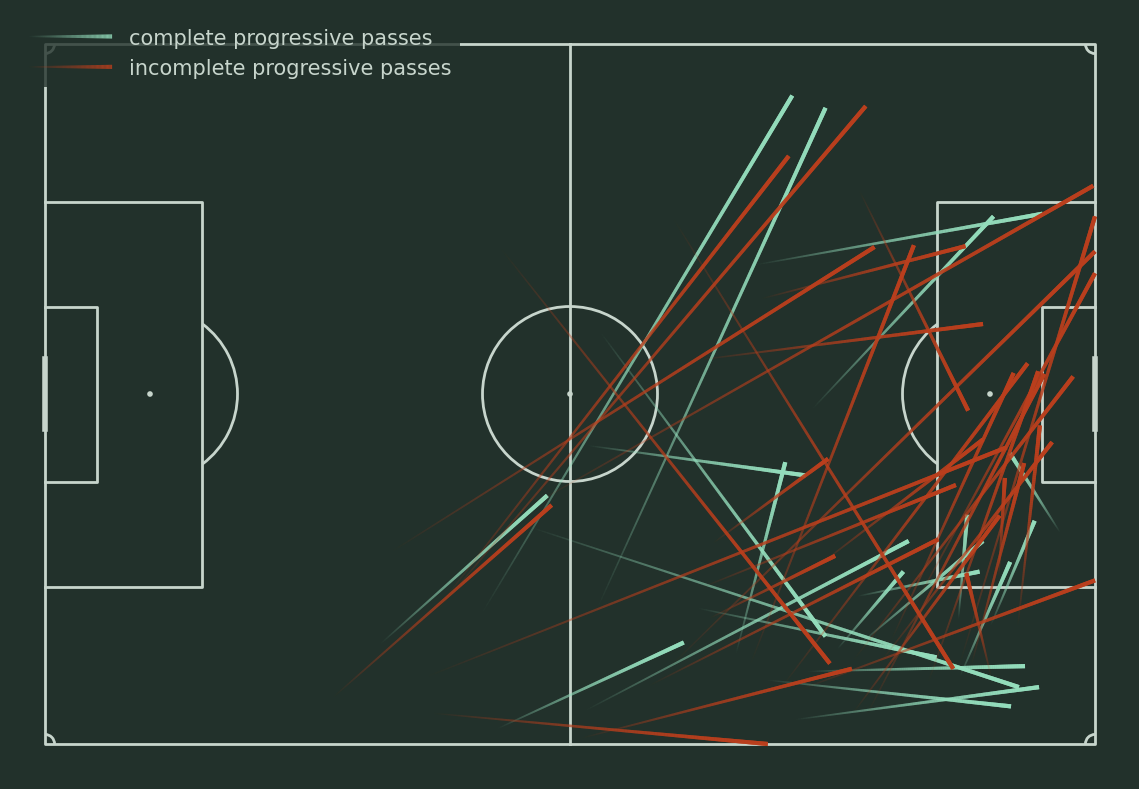

In [32]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_prog_comp['x_start'], ziyech_prog_comp['y_start'], ziyech_prog_comp['x_end'], ziyech_prog_comp['y_end'],
            ax = ax, color = '#94DDBC', lw = 3, transparent = True, comet = True, label = 'complete progressive passes')

pitch.lines(ziyech_prog_incomp['x_start'], ziyech_prog_incomp['y_start'], ziyech_prog_incomp['x_end'], ziyech_prog_incomp['y_end'],
            ax = ax, color = '#BA3F1D', lw = 3, transparent = True, comet = True, label = 'incomplete progressive passes')

ax.legend(facecolor='#22312b', edgecolor='None', fontsize=15, labelcolor = '#c7d5cc', loc='upper left', handlelength=4)

# Passes into the penalty area

In this step I wanted to analyse Ziyech's passes into the penalty area. I repeated the process made with the progressive passes, calculating the number of attempts from each player in the dataset, then comparing to the team's total

To find out which of the passes ended in the penalty area, I used below the 'x' and 'y' coordinates provided by StatsBomb

In [33]:
ppa = df[(df['x_end'] > 102) & (df['x_end'] < 120) & (df['y_end'] > 18) & (df['y_end'] < 62)]

In [34]:
ppa['pass_type'].unique()

array([nan, 'Corner', 'Free Kick', 'Recovery', 'Throw-in', 'Interception',
       'Goal Kick'], dtype=object)

In [35]:
ppa = ppa[ppa['pass_type'].isna()]

In [36]:
ppa_players = ppa.groupby(['player', 'team']).count().sort_values(['id'], ascending = False).reset_index()[['player', 'team', 'id']]

In [37]:
ppa_players.rename(columns = {'id':'ppa'}, inplace = True)

In [38]:
ppa_players.head(10)

,player,team,ppa
0,Kylian Mbappé Lottin,France,39
1,Ivan Perišić,Croatia,38
2,Ángel Fabián Di María Hernández,Argentina,33
3,Ousmane Dembélé,France,31
4,Lionel Andrés Messi Cuccittini,Argentina,31
5,Rodrigo Javier De Paul,Argentina,30
6,Hakim Ziyech,Morocco,29
7,Antoine Griezmann,France,26
8,Luka Modrić,Croatia,25
9,Luke Shaw,England,24


In [39]:
ppa_teams = ppa_players[['team', 'ppa']].groupby(['team']).sum().sort_values(['ppa'], ascending = False).reset_index()

In [40]:
ppa_complete = pd.merge(ppa_players, ppa_teams, how = 'left', on = 'team')

In [41]:
ppa_complete.rename(columns = {'ppa_x':'ppa_player', 'ppa_y':'ppa_team'}, inplace = True)

In [42]:
ppa_complete.head(10)

,player,team,ppa_player,ppa_team
0,Kylian Mbappé Lottin,France,39,174
1,Ivan Perišić,Croatia,38,212
2,Ángel Fabián Di María Hernández,Argentina,33,185
3,Ousmane Dembélé,France,31,174
4,Lionel Andrés Messi Cuccittini,Argentina,31,185
5,Rodrigo Javier De Paul,Argentina,30,185
6,Hakim Ziyech,Morocco,29,115
7,Antoine Griezmann,France,26,174
8,Luka Modrić,Croatia,25,212
9,Luke Shaw,England,24,140


In [43]:
ppa_complete['ppa%'] = ppa_complete['ppa_player'] / ppa_complete['ppa_team'] * 100
ppa_complete.sort_values('ppa%', ascending = False).head(10)

,player,team,ppa_player,ppa_team,ppa%
14,Kevin De Bruyne,Belgium,21,68,30.882353
13,Dušan Tadić,Serbia,22,78,28.205128
127,Joel Nathaniel Campbell Samuels,Costa Rica,8,30,26.666667
66,Ismaeel Mohammad Mohammad,Qatar,12,45,26.666667
23,Filip Kostić,Serbia,20,78,25.641026
6,Hakim Ziyech,Morocco,29,115,25.217391
22,Hirving Rodrigo Lozano Bahena,Mexico,20,84,23.809524
36,Saud Abdullah Abdul Hamid,Saudi Arabia,16,68,23.529412
27,Ismaïla Sarr,Senegal,18,80,22.500000
0,Kylian Mbappé Lottin,France,39,174,22.413793


In [44]:
ziyech_ppa = ppa[ppa['player'] == 'Hakim Ziyech']
ziyech_ppa.shape

(29, 55)

In [45]:
ziyech_ppa_comp = ziyech_ppa[ziyech_ppa['pass_outcome'].isna()]
ziyech_ppa_comp.shape

(8, 55)

In [46]:
ziyech_ppa_incomp = ziyech_ppa[ziyech_ppa['pass_outcome'].notnull()]
ziyech_ppa_incomp.shape

(21, 55)

Plotting all passes into the penalty area from Ziyech during the FIFA World Cup 2022, categorizing them according to their outcome (complete or incomplete)

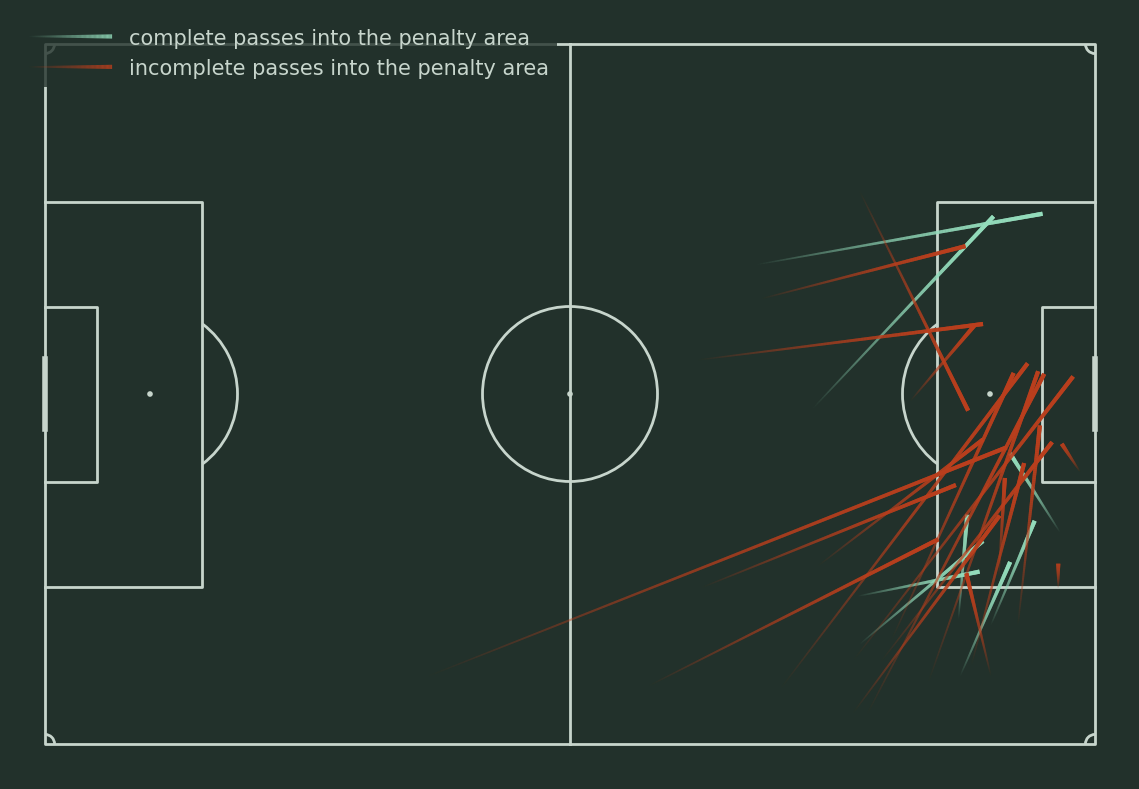

In [47]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_ppa_comp['x_start'], ziyech_ppa_comp['y_start'], ziyech_ppa_comp['x_end'], ziyech_ppa_comp['y_end'],
            ax = ax, color = '#94DDBC', lw = 3, transparent = True, comet = True, label = 'complete passes into the penalty area')

pitch.lines(ziyech_ppa_incomp['x_start'], ziyech_ppa_incomp['y_start'], ziyech_ppa_incomp['x_end'], ziyech_ppa_incomp['y_end'],
            ax = ax, color = '#BA3F1D', lw = 3, transparent = True, comet = True, label = 'incomplete passes into the penalty area')

ax.legend(facecolor='#22312b', edgecolor='None', fontsize=15, labelcolor = '#c7d5cc', loc='upper left', handlelength=4)

In [48]:
ziyech_ppa_right = ziyech_ppa[ziyech_ppa['pass_body_part'] == 'Right Foot']
ziyech_ppa_right.shape

(6, 55)

In [49]:
ziyech_ppa_left = ziyech_ppa[ziyech_ppa['pass_body_part'] == 'Left Foot']
ziyech_ppa_left.shape

(22, 55)

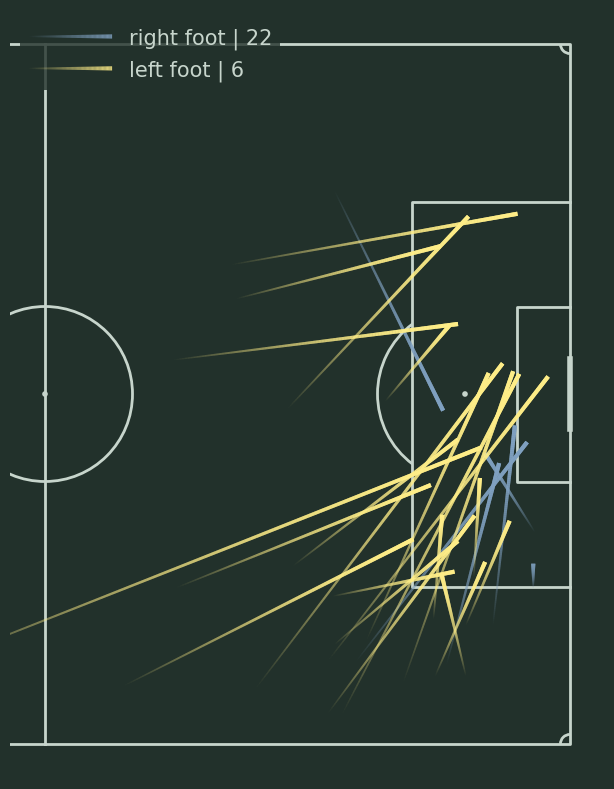

In [50]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc', half = True)
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_ppa_right['x_start'], ziyech_ppa_right['y_start'], ziyech_ppa_right['x_end'], ziyech_ppa_right['y_end'],
            ax = ax, color = '#80A1C1', lw = 3, transparent = True, comet = True, label = 'right foot | 22')

pitch.lines(ziyech_ppa_left['x_start'], ziyech_ppa_left['y_start'], ziyech_ppa_left['x_end'], ziyech_ppa_left['y_end'],
            ax = ax, color = '#FFEE88', lw = 3, transparent = True, comet = True, label = 'left foot | 6')

ax.legend(facecolor='#22312b', edgecolor='None', fontsize=15, labelcolor = '#c7d5cc', loc='upper left', handlelength=4)

To further analyse these passes, I wanted to understand exactly how Ziyech tried to find his teammates in the penalty area and grouped the attempts according to the pass height

In [51]:
ziyech_ppa.groupby('pass_height').count().sort_values(['id'], ascending = False).reset_index()[['pass_height', 'id']]

,pass_height,id
0,High Pass,15
1,Ground Pass,9
2,Low Pass,5


In [52]:
gp = ziyech_ppa[ziyech_ppa['pass_height'] == 'Ground Pass']

lp = ziyech_ppa[ziyech_ppa['pass_height'] == 'Low Pass']

hp = ziyech_ppa[ziyech_ppa['pass_height'] == 'High Pass']

Plotting all passes into the penalty area from Ziyech during the FIFA World Cup 2022, categorizing them according to their height (ground, low or high)

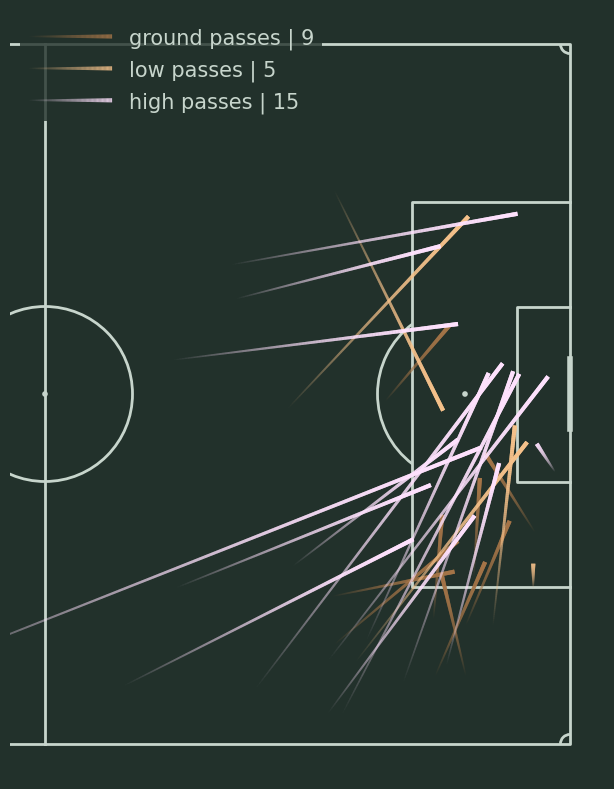

In [53]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc', half = True)
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(gp['x_start'], gp['y_start'], gp['x_end'], gp['y_end'],
            ax = ax, color = '#A57548', lw = 3, transparent = True, comet = True, label = 'ground passes | 9')

pitch.lines(lp['x_start'], lp['y_start'], lp['x_end'], lp['y_end'],
            ax = ax, color = '#F6C28B', lw = 3, transparent = True, comet = True, label = 'low passes | 5')

pitch.lines(hp['x_start'], hp['y_start'], hp['x_end'], hp['y_end'],
            ax = ax, color = '#FFE2FE', lw = 3, transparent = True, comet = True, label = 'high passes | 15')

ax.legend(facecolor='#22312b', edgecolor='None', fontsize=15, labelcolor = '#c7d5cc', loc='upper left', handlelength=4)

# Frames

StatsBomb also provides data that allows us to visualize where on the pitch were the players beside Ziyech. I used this information to plot two of the Moroccan high pass attempts into the penalty area

Specifically in the cell below, I wanted to know the match_id of the matches in which he attempted a high pass into the penalty area

In [54]:
ziyech_ppa[ziyech_ppa['pass_height'] == 'High Pass'].groupby('match_id').count().sort_values('id', ascending = False)[['id']]

,id
match_id,
3869552,4
3869684,3
3857276,2
3869486,2
3857277,2
3857283,1
3869220,1


Importing the events from one of the matches listed above

In [55]:
match_events = sb.events(match_id= 3869552)

In the file below (also with information from the match with the id '3869552) I get the StatsBomb 360 data that allows me to plot Ziyech's teammates and oponets

In [56]:
match_360_df = pd.read_json('3869552-googlecolab.json')

Each row of the 'freeze_frame' column is associated with a match event and contains a dictionary with the location of different players in that specific event

In [57]:
match_360_df.columns

Index(['event_uuid', 'visible_area', 'freeze_frame'], dtype='object')

Merging the two dataframes used in this step of the analysis. 'match_events' contains the StatsBomb data that I've been using since the beginning of this file. 'match_360_df' contains the StatsBomb 360 data

In [58]:
events_360 = pd.merge(left = match_events, right = match_360_df, left_on = 'id', right_on = 'event_uuid', how = 'left')

In [59]:
events_360.columns

Index(['50_50', 'ball_receipt_outcome', 'ball_recovery_recovery_failure',
       'block_offensive', 'block_save_block', 'carry_end_location',
       'clearance_aerial_won', 'clearance_body_part', 'clearance_head',
       'clearance_left_foot', 'clearance_right_foot', 'counterpress',
       'dribble_no_touch', 'dribble_nutmeg', 'dribble_outcome',
       'dribble_overrun', 'duel_outcome', 'duel_type', 'duration',
       'foul_committed_advantage', 'foul_committed_card',
       'foul_committed_offensive', 'foul_committed_type', 'foul_won_advantage',
       'foul_won_defensive', 'goalkeeper_body_part', 'goalkeeper_end_location',
       'goalkeeper_outcome', 'goalkeeper_position',
       'goalkeeper_shot_saved_to_post', 'goalkeeper_technique',
       'goalkeeper_type', 'id', 'index', 'injury_stoppage_in_chain',
       'interception_outcome', 'location', 'match_id', 'minute', 'off_camera',
       'out', 'pass_aerial_won', 'pass_angle', 'pass_assisted_shot_id',
       'pass_body_part', 'pass_

Creating a new variable to include only high passes into the penalty area from Ziyech

In [60]:
events_360_ziyech = events_360[(events_360['player_id'] == 5237) & (events_360['type'] == 'Pass') & (events_360['pass_height'] == 'High Pass') & (events_360['pass_type'].isna())]

Splitting the 'location' and 'end_location' columns to get the 'x' and 'y' coordinates from each pass (at its start and also at its end) in different columns, so I was able to filter the passes that ended in the penalty area

In [61]:
events_360_ziyech[['x_start', 'y_start']] = pd.DataFrame(events_360_ziyech.location.tolist(), index = events_360_ziyech.index)
events_360_ziyech[['x_end', 'y_end']] = pd.DataFrame(events_360_ziyech.pass_end_location.tolist(), index = events_360_ziyech.index)

/tmp/ipykernel_24336/3065082254.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  events_360_ziyech[['x_start', 'y_start']] = pd.DataFrame(events_360_ziyech.location.tolist(), index = events_360_ziyech.index)
/tmp/ipykernel_24336/3065082254.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  events_360_ziyech[['x_start', 'y_start']] = pd.DataFrame(events_360_ziyech.location.tolist(), index = events_360_ziyech.index)
/tmp/ipykernel_24336/3065082254.py:2: SettingWithCopyWarning: 
A value is trying to be set

In [62]:
events_360_ziyech = events_360_ziyech[(events_360_ziyech['x_end'] > 102) & (events_360_ziyech['x_end'] < 120) & (events_360_ziyech['y_end'] > 18) & (events_360_ziyech['y_end'] < 62)]

Ziyech had four high pass attemps into the penalty area during this match (all listed below). Two of them had information available in the 'freeze_frame' column. I designated one variable to each of these two events to plot the plays

In [63]:
events_360_ziyech[['player', 'timestamp', 'pass_recipient', 'minute', 'pass_height', 'pass_type', 'pass_outcome', 'x_start', 'y_start', 'x_end', 'y_end', 'freeze_frame']]

,player,timestamp,pass_recipient,minute,pass_height,pass_type,pass_outcome,x_start,y_start,x_end,y_end,freeze_frame
228,Hakim Ziyech,00:18:46.190,Sofiane Boufal,18,High Pass,NaN,Incomplete,94.0,76.5,114.2,37.7,NaN
713,Hakim Ziyech,00:17:49.755,Youssef En-Nesyri,62,High Pass,NaN,Incomplete,96.8,68.0,110.7,37.6,"[{'teammate': False, 'actor': False, 'keeper':..."
745,Hakim Ziyech,00:21:45.790,Yahia Attiyat allah,66,High Pass,NaN,NaN,81.4,25.2,114.0,19.4,NaN
998,Hakim Ziyech,00:49:12.942,Zakaria Aboukhlal,94,High Pass,NaN,Pass Offside,74.7,36.1,107.2,32.0,"[{'teammate': True, 'actor': False, 'keeper': ..."


In [64]:
play1 = events_360_ziyech[1:2]

play2 = events_360_ziyech[3:4]

Plotting two of the high passes into the penalty area from Ziyech during the FIFA World Cup 2022

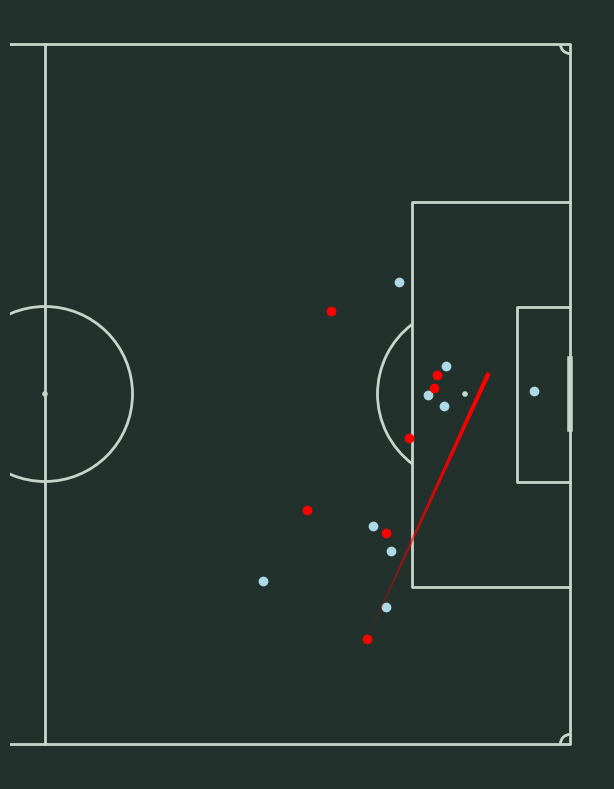

In [65]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc', half = True)
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(xstart = play1['x_start'], ystart = play1['y_start'], xend = play1['x_end'], yend = play1['y_end'],
            ax = ax, color = 'Red', lw = 3, transparent = True, comet = True)

for player in play1.iloc[0]['freeze_frame']:
  if player['teammate']:
    color = 'red'
  else:
    color = 'lightblue'

  pitch.scatter(x = player['location'][0], y = player['location'][1], ax = ax, c = color)

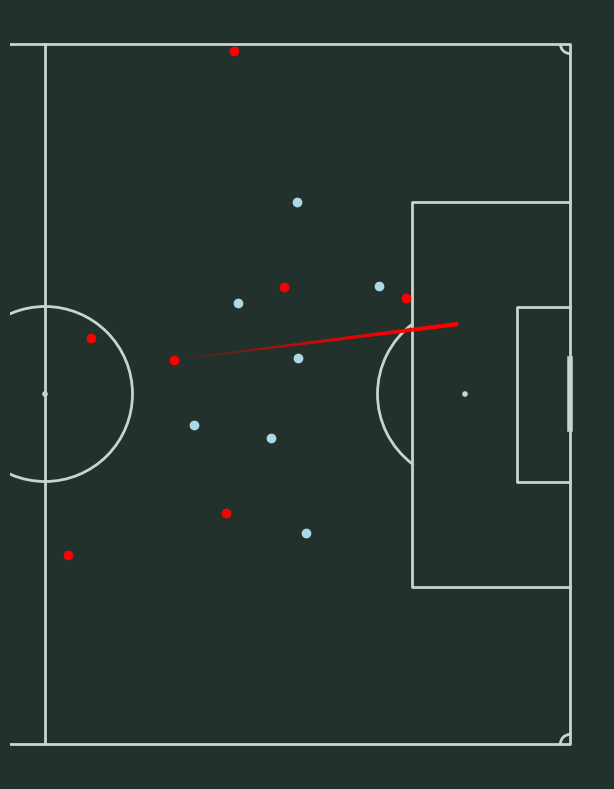

In [66]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc', half = True)
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(xstart = play2['x_start'], ystart = play2['y_start'], xend = play2['x_end'], yend = play2['y_end'],
            ax = ax, color = 'Red', lw = 3, transparent = True, comet = True)

for player in play2.iloc[0]['freeze_frame']:
  if player['teammate']:
    color = 'red'
  else:
    color = 'lightblue'

  pitch.scatter(x = player['location'][0], y = player['location'][1], ax = ax, c = color)

# Shot assists

I created the variable 'shot_assist' to filter only the passes that directly led to a shot

In [67]:
shot_assist = df[df['pass_shot_assist'].notnull()]

Grouping the dataframe by the player name, getting the top values in this attribute, and then finding Ziyech's number

In [68]:
shot_assist_players = shot_assist.groupby('player').count().sort_values('id', ascending = False).reset_index()[['player', 'id']]
shot_assist_players.rename(columns = {'id':'shot_assists'}, inplace = True)

shot_assist_players.head()

,player,shot_assists
0,Antoine Griezmann,17
1,Lionel Andrés Messi Cuccittini,16
2,Ousmane Dembélé,10
3,Theo Bernard François Hernández,10
4,Cody Mathès Gakpo,10


In [69]:
shot_assist_players.loc[shot_assist_players['player'] == 'Hakim Ziyech']

,player,shot_assists
26,Hakim Ziyech,6


In [70]:
ziyech_shot_assist = df[(df['player'] == 'Hakim Ziyech') & (df['pass_shot_assist'].notnull())]

Plotting all shot assists from Ziyech during the FIFA World Cup 2022

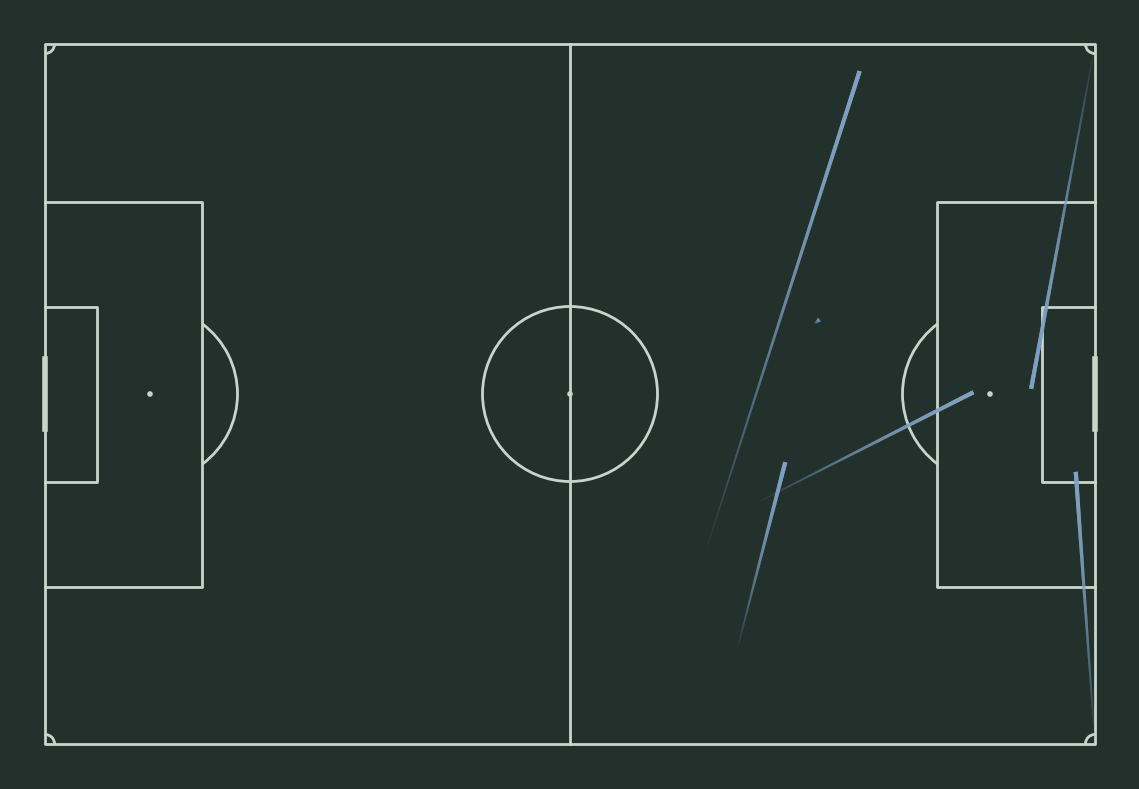

In [71]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_shot_assist['x_start'], ziyech_shot_assist['y_start'], ziyech_shot_assist['x_end'], ziyech_shot_assist['y_end'],
            ax = ax, color = '#80A1C1', lw = 3, transparent = True, comet = True)

# Through balls

In this step, I wanted to analyze Ziyech's through balls. I repeated the process made with the shot assists, getting the top players in this stat and then checking Ziyech's rank

In [72]:
tb = df[df['pass_through_ball'].notnull()]

In [73]:
tb_players = tb.groupby('player').count().sort_values('id', ascending = False).reset_index()[['player', 'id']]
tb_players.rename(columns = {'id':'through_balls'}, inplace = True)

tb_players.head()

,player,through_balls
0,Lionel Andrés Messi Cuccittini,8
1,Enzo Fernandez,7
2,Rodrigo Javier De Paul,7
3,Bruno Miguel Borges Fernandes,5
4,Kevin De Bruyne,4


In [74]:
tb_players.loc[tb_players['player'] == 'Hakim Ziyech']

,player,through_balls
6,Hakim Ziyech,3


In [75]:
ziyech_tb = df[(df['player'] == 'Hakim Ziyech') & (df['pass_through_ball'].notnull())]

In [76]:
ziyech_tb[['player', 'match_id', 'timestamp', 'minute', 'pass_height', 'pass_type', 'pass_outcome', 'x_start', 'y_start', 'x_end', 'y_end']]

,player,match_id,timestamp,minute,pass_height,pass_type,pass_outcome,x_start,y_start,x_end,y_end
38746,Hakim Ziyech,3869486,00:37:19.933,37,High Pass,NaN,Incomplete,43.9,72.2,109.9,46.1
47424,Hakim Ziyech,3869552,00:49:12.942,94,High Pass,NaN,Pass Offside,74.7,36.1,107.2,32.0
59049,Hakim Ziyech,3857283,00:39:35.881,84,Low Pass,NaN,Incomplete,93.1,16.8,105.5,41.9


Plotting all through balls from Ziyech during the FIFA World Cup 2022

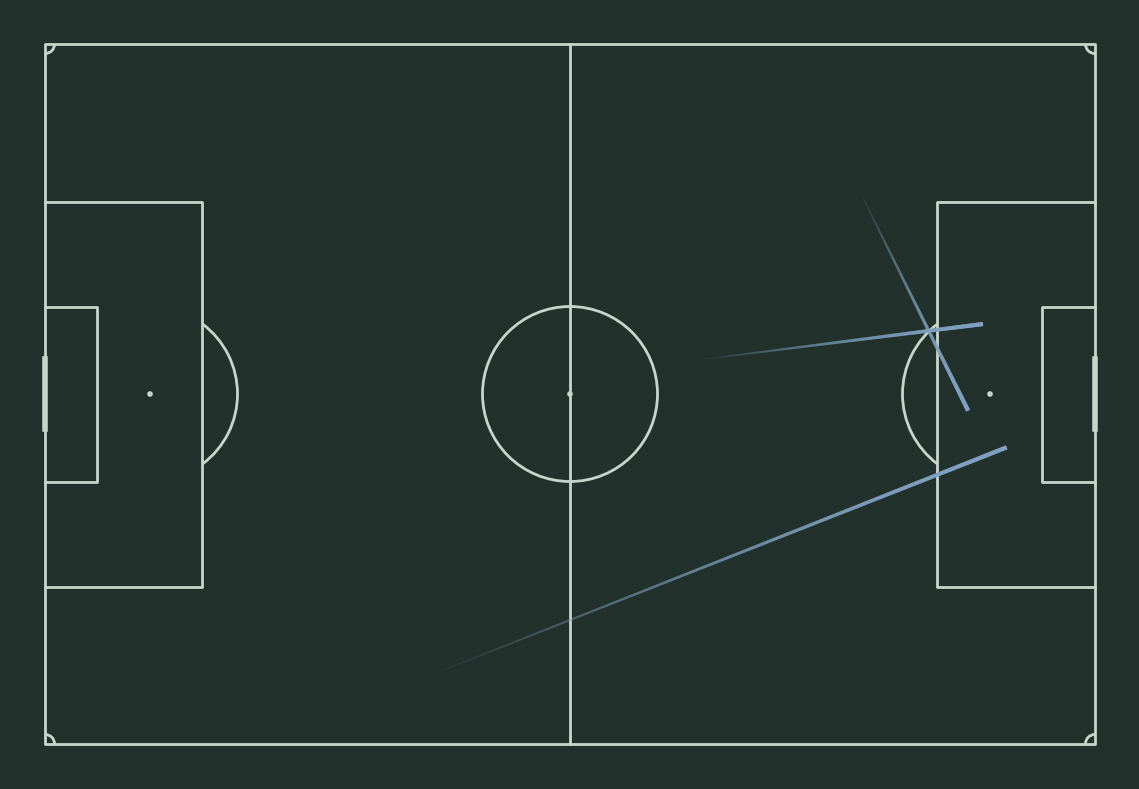

In [77]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_tb['x_start'], ziyech_tb['y_start'], ziyech_tb['x_end'], ziyech_tb['y_end'],
            ax = ax, color = '#80A1C1', lw = 3, transparent = True, comet = True)

# Pass lenght

According to StatsBomb, the values in the 'pass_length' column are presented in yards. To separate the short and the long ones, I needed to convert the distance to meters

In [78]:
ziyech_passes['pass_length'] = ziyech_passes['pass_length'] * 0.9144

/tmp/ipykernel_24336/1088409901.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ziyech_passes['pass_length'] = ziyech_passes['pass_length'] * 0.9144


The definition of long and short passes may vary according to the data provider. In this case, I'll consider short passes as ground attempts that move the ball less than 30 meters and long passes as high attempts that move the ball more than 30 meters

In [79]:
ziyech_short = ziyech_passes[(ziyech_passes['pass_length'] < 30) & (ziyech_passes['pass_height'] == 'Ground Pass')]
ziyech_short.shape

(186, 52)

In [80]:
ziyech_long = ziyech_passes[(ziyech_passes['pass_length'] > 30) & (ziyech_passes['pass_height'] == 'High Pass')]
ziyech_long.shape

(50, 52)

Plotting all short and long passes from Ziyech during the FIFA World Cup 2022

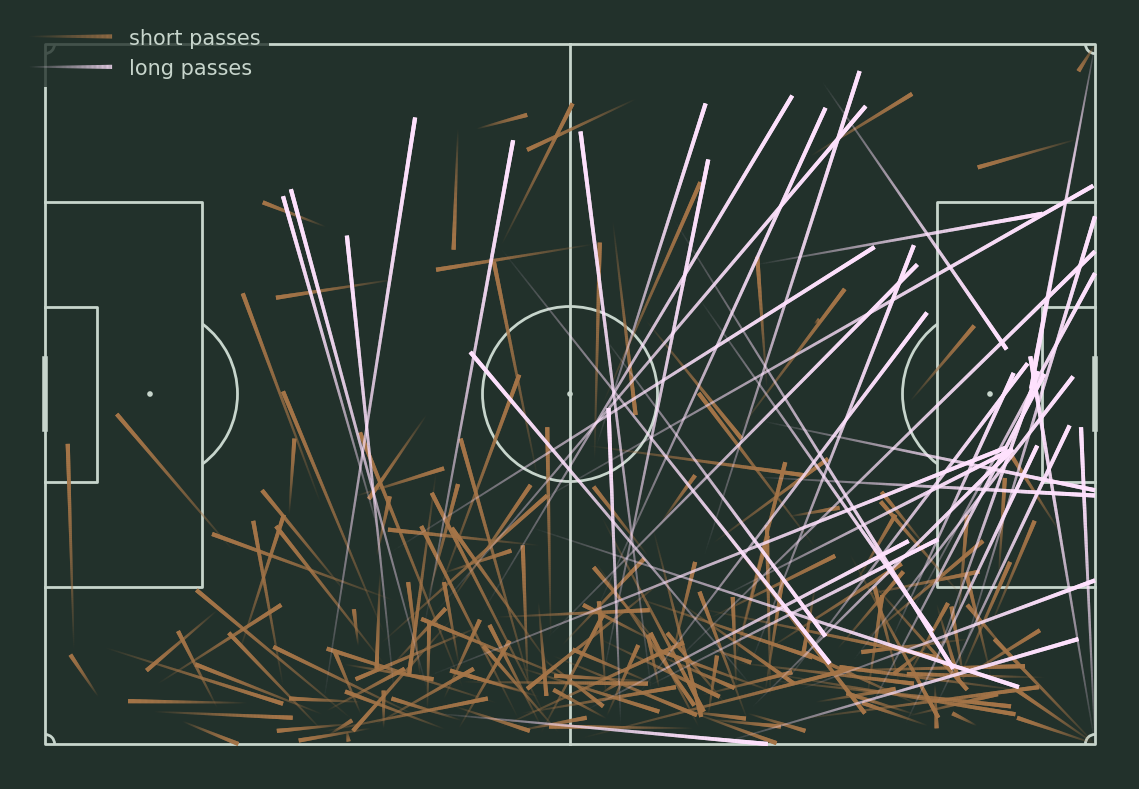

In [81]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_short['x_start'], ziyech_short['y_start'], ziyech_short['x_end'], ziyech_short['y_end'],
            ax = ax, color = '#A57548', lw = 3, transparent = True, comet = True, label = 'short passes')

pitch.lines(ziyech_long['x_start'], ziyech_long['y_start'], ziyech_long['x_end'], ziyech_long['y_end'],
            ax = ax, color = '#FFE2FE', lw = 3, transparent = True, comet = True, label = 'long passes')

ax.legend(facecolor='#22312b', edgecolor='None', fontsize=15, labelcolor = '#c7d5cc', loc='upper left', handlelength=4)

# Pass recipients and body parts

Counting the number of passes according to the pass recipient


In [82]:
ziyech_passes['pass_recipient'].value_counts()

,count
pass_recipient,
Achraf Hakimi Mouh,86
Azzedine Ounahi,37
Sofyan Amrabat,25
Youssef En-Nesyri,22
Sofiane Boufal,19
Romain Saïss,10
Jawad El Yamiq,10
Selim Amallah,7
Achraf Dari,7


In [83]:
ziyech_hakimi = ziyech_passes[ziyech_passes['pass_recipient'] == 'Achraf Hakimi Mouh']

Plotting all passe attempts from Ziyech to Hakimi during the FIFA World Cup 2022

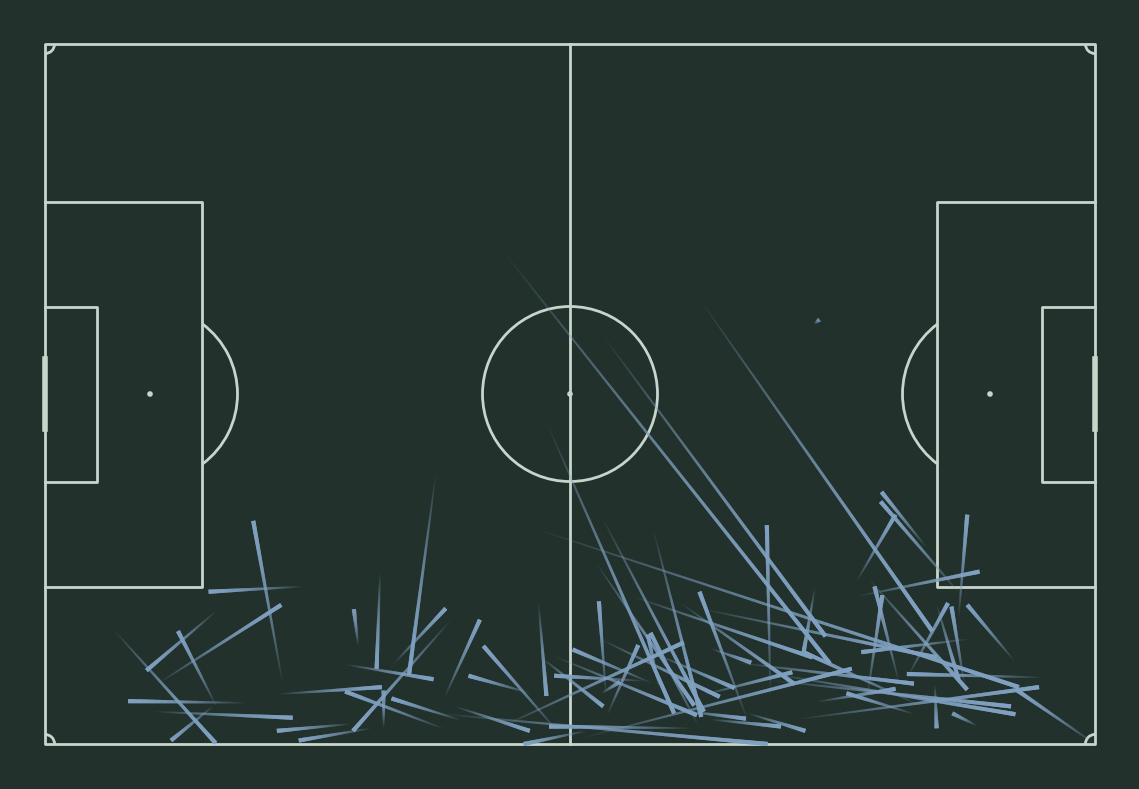

In [84]:
pitch = Pitch(pitch_type = 'statsbomb', corner_arcs = True, pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize = (12, 8), tight_layout = True)
fig.set_facecolor('#22312b')

pitch.lines(ziyech_hakimi['x_start'], ziyech_hakimi['y_start'], ziyech_hakimi['x_end'], ziyech_hakimi['y_end'],
            ax = ax, color = '#80A1C1', lw = 3, transparent = True, comet = True)

Counting the number of passes according to the body part used in the play


In [85]:
ziyech_passes['pass_body_part'].value_counts()

,count
pass_body_part,
Left Foot,256
Right Foot,30
Head,4
No Touch,1
